Análise Titanic

In [193]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [194]:
df = pd.read_csv('titanic.csv')

In [195]:
display(df)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [196]:
df_teste = df

In [197]:
df_teste = df_teste.drop(
    columns=[
        "Ticket",
        "Cabin",
        "Fare",
        "Parch",
        "Embarked",
        "SibSp",
        "Pclass",
        "PassengerId"
    ]
)

Limpeza de Dados

In [198]:
df_teste.Sex.value_counts(dropna = False)

Sex
male      577
female    314
Name: count, dtype: int64

In [199]:
df_copia = df_teste

In [200]:
df_copia = pd.get_dummies(df_copia["Sex"], dtype = int)

In [201]:
df_copia

,female,male
0,0,1
1,1,0
2,1,0
3,1,0
4,0,1
...,...,...
886,0,1
887,1,0
888,1,0
889,0,1


In [202]:
df_copia = df_copia.drop(
    columns = [
        "male"

    ]
)

In [203]:
df_teste["Female"] = df_copia["female"]

In [204]:
df_teste

,Survived,Name,Sex,Age,Female
0,0,"Braund, Mr. Owen Harris",male,22.0,0
1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1
2,1,"Heikkinen, Miss. Laina",female,26.0,1
3,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1
4,0,"Allen, Mr. William Henry",male,35.0,0
...,...,...,...,...,...
886,0,"Montvila, Rev. Juozas",male,27.0,0
887,1,"Graham, Miss. Margaret Edith",female,19.0,1
888,0,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1
889,1,"Behr, Mr. Karl Howell",male,26.0,0


In [205]:
df_teste["Title"] = df_teste["Name"]

In [206]:
df_teste["Title"] = df_teste["Name"].str.extract('(Mrs|Mr|Miss|Master)')

In [207]:
df_teste

,Survived,Name,Sex,Age,Female,Title
0,0,"Braund, Mr. Owen Harris",male,22.0,0,Mr
1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,Mrs
2,1,"Heikkinen, Miss. Laina",female,26.0,1,Miss
3,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,Mrs
4,0,"Allen, Mr. William Henry",male,35.0,0,Mr
...,...,...,...,...,...,...
886,0,"Montvila, Rev. Juozas",male,27.0,0,NaN
887,1,"Graham, Miss. Margaret Edith",female,19.0,1,Miss
888,0,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,Miss
889,1,"Behr, Mr. Karl Howell",male,26.0,0,Mr


In [208]:
df_teste = df_teste.drop(
    columns = [
        "Name",
        "Sex"
    ]
)

In [209]:
df_teste

,Survived,Age,Female,Title
0,0,22.0,0,Mr
1,1,38.0,1,Mrs
2,1,26.0,1,Miss
3,1,35.0,1,Mrs
4,0,35.0,0,Mr
...,...,...,...,...
886,0,27.0,0,NaN
887,1,19.0,1,Miss
888,0,NaN,1,Miss
889,1,26.0,0,Mr


Transformação de dados categóricos em colunas

Retiramos a coluna Sex_male pois ela já é descoberta com a coluna Sex_female... Retiramos aa coluna TitleMaster pois a maioria é 0 pois já são descobertos em Title_Miss

Imputação de dados:

In [210]:
from sklearn.impute import SimpleImputer

In [211]:
coluna = df_teste[["Age"]]

In [212]:
df_teste['Age'].median()

np.float64(28.0)

In [213]:
imputacao = SimpleImputer(strategy = "median")

In [214]:
df_teste["Age"] = imputacao.fit_transform(coluna)

Preenchimento de NaN pela mediana (28.0) de valores contidos na tabela.

In [215]:
df_teste

,Survived,Age,Female,Title
0,0,22.0,0,Mr
1,1,38.0,1,Mrs
2,1,26.0,1,Miss
3,1,35.0,1,Mrs
4,0,35.0,0,Mr
...,...,...,...,...
886,0,27.0,0,NaN
887,1,19.0,1,Miss
888,0,28.0,1,Miss
889,1,26.0,0,Mr


In [216]:
df_num = df_teste.select_dtypes(include=["number","bool"])

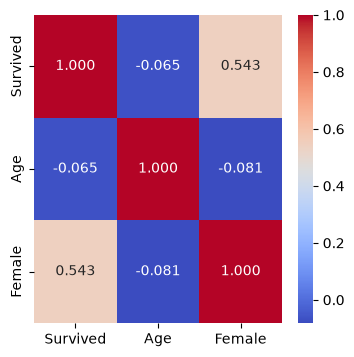

In [217]:
correlacao = df_num.corr()

plt.figure(figsize=(4, 4))

sns.heatmap(
    correlacao,
    annot = True,
    cmap = "coolwarm",
    fmt=".3f"
)

plt.title = "Correlação entre colunas do Titanic"

Treinamento e Teste:

In [218]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, recall_score, precision_score, f1_score

In [219]:
Y = df_teste["Survived"]
X = df_teste.drop(columns="Survived").select_dtypes(include='number')

In [220]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
print(" train_test_split feito")
Y_train

 train_test_split feito


331    0
733    0
382    0
704    0
813    0
      ..
106    1
270    0
860    0
435    1
102    0
Name: Survived, Length: 712, dtype: int64

KNN

In [221]:
knn = make_pipeline(
    SimpleImputer(strategy="mean"),
    StandardScaler(),
    KNeighborsClassifier()
)

In [222]:
knn.fit(X_train, Y_train)
resultado_knn = knn.predict(X_test)
acuracia_knn = accuracy_score(Y_test, resultado_knn)
print(f"Acurácia: {acuracia_knn:.2%}")

Acurácia: 77.09%


In [223]:
DecisionTreeClassifier

sklearn.tree._classes.DecisionTreeClassifier

In [224]:
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, Y_train)
resultado_tree = tree.predict(X_test)
acuracia_tree = accuracy_score(Y_test, resultado_tree)
print(f"Acurácia: {acuracia_tree:.2%}")

Acurácia: 77.65%


Logistic Regression

In [225]:
logistic = make_pipeline (
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

In [226]:
logistic.fit(X_train, Y_train)
resultado_log = logistic.predict(X_test)
acuracia_log = accuracy_score(Y_test, resultado_log)

print(f"Acurácia: {acuracia_log:.2%}")

Acurácia: 78.21%


Recall | F1 | Precision

In [227]:
precision_knn = precision_score(Y_test, resultado_knn)
recall_knn = recall_score(Y_test, resultado_knn)
f1_knn = f1_score(Y_test, resultado_knn)

precision_tree = precision_score(Y_test, resultado_tree)
recall_tree = recall_score(Y_test, resultado_tree)
f1_tree = f1_score(Y_test, resultado_tree)

precision_log = precision_score(Y_test, resultado_log)
recall_log = recall_score(Y_test, resultado_log)
f1_log = f1_score(Y_test, resultado_log)

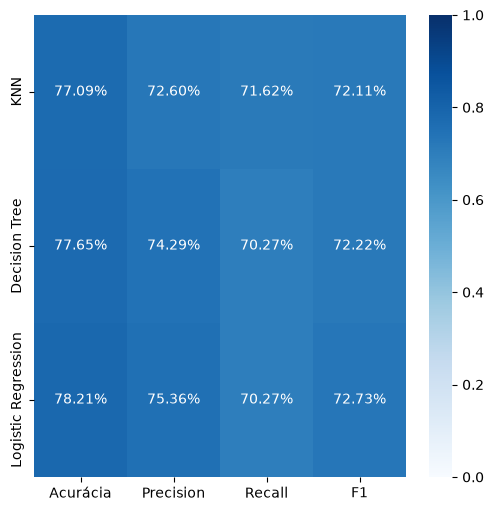

In [231]:
metricas = pd.DataFrame([
        [acuracia_knn, precision_knn, recall_knn, f1_knn],
        [acuracia_tree, precision_tree, recall_tree, f1_tree],
        [acuracia_log, precision_log, recall_log, f1_log]
    ],
    index = ["KNN", "Decision Tree", "Logistic Regression"],
    columns = ["Acurácia", "Precision", "Recall", "F1"]
)

plt.figure(figsize=(6, 6))

sns.heatmap(
    metricas,
    annot=True,
    cmap="Blues",
    fmt=".2%",
    vmin=0,
    vmax=1
)

plt.title = ("Acurácia dos modelos")
plt.show()